# AutoML Benchmark — AutoGluon vs. CatBoost

Step 2 of `PROJECT_PLAN.md`. In `Modeling.ipynb` we chose **CatBoost** (D-22). Here we let **AutoGluon** try many
models automatically — CatBoost, LightGBM, XGBoost, random forest, extra trees, kNN, linear models and neural
networks, combined into stacked ensembles — to see if something **clearly better** exists.

**Decision rule (D-10, agreed before this run):** we switch to the AutoML model **only if it beats CatBoost by more
than 0.01 ROC-AUC** (or clearly improves recall at our threshold) on the same test set.

**Setup (decisions in `DECISIONS.md`):**

| Setting | Value |
|---|---|
| Environment | `da-ml-automl` (`environment-automl.yml`), **not** `da-ml` |
| Train/test split | Same rows as `Modeling.ipynb`, read from `data/splits/train_test_split.csv` |
| Target | Yes/no: prediabetes or diabetes (D-08), no balancing (D-19) |
| AutoGluon preset | `best_quality` (bagging + stacking) |
| Time budget | 1 hour |
| Metric AutoGluon optimises | ROC-AUC |
| Threshold | 80% recall, chosen on out-of-fold predictions (D-23) |

> **Runtime:** about 1 hour 10 minutes. **Kernel:** select the `da-ml-automl` environment for this notebook.

## 1. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

from autogluon.tabular import TabularPredictor
from catboost import CatBoostClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score)

SEED = 42
TIME_LIMIT = 60 * 60                                  # 1 hour (D-29)
MODEL_DIR = Path("../../models/autogluon_benchmark")  # large, not committed (.gitignore)
TARGET_RECALL = 0.80                                  # D-23

## 2. Load data and the shared split

Same loading and target as `Modeling.ipynb`. The split file maps each row of the raw CSV to `train` or `test`.

In [2]:
df = pd.read_csv("../../data/raw_data/diabetes_012_health_indicators_BRFSS2015.csv").astype(int)
df["diabetes"] = (df.pop("Diabetes_012") > 0).astype(int)

split = pd.read_csv("../../data/splits/train_test_split.csv", index_col="row")["split"]
assert split.index.equals(df.index), "split file does not match the dataset"

train = df[split == "train"]
test = df[split == "test"]
print(f"Train: {len(train):,} rows ({train['diabetes'].mean():.1%} positive)")
print(f"Test:  {len(test):,} rows ({test['diabetes'].mean():.1%} positive)")

Train: 202,944 rows (15.8% positive)
Test:  50,736 rows (15.8% positive)


## 3. Helpers: the same metrics as `Modeling.ipynb`

In [3]:
def precision_at_recall(y_true, proba, target_recall=TARGET_RECALL):
    precision, recall, _ = precision_recall_curve(y_true, proba)
    return precision[recall >= target_recall].max()


def score(y_true, proba):
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Precision@80%recall": precision_at_recall(y_true, proba),
        "Brier": brier_score_loss(y_true, proba),
    }


def threshold_for_recall(y_true, proba, target_recall=TARGET_RECALL):
    """Highest threshold that still reaches the recall target."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    return thresholds[np.where(recall[:-1] >= target_recall)[0].max()]


def evaluate_on_test(name, proba_test, threshold):
    flagged = proba_test >= threshold
    y = test["diabetes"]
    return {"model": name, **score(y, proba_test), "threshold": threshold,
            "recall": recall_score(y, flagged), "precision": precision_score(y, flagged),
            "F1": f1_score(y, flagged), "accuracy": accuracy_score(y, flagged), "share flagged": flagged.mean()}

## 4. Train AutoGluon

`best_quality` trains every model type with **bagging** (each model is trained on several folds of the training
data, which also gives out-of-fold predictions) and then **stacks** them: a second layer of models learns from the
first layer's predictions. AutoGluon stops when the time budget is used up.

The test set is **not** given to AutoGluon.

In [4]:
start = time.time()
predictor = TabularPredictor(label="diabetes", eval_metric="roc_auc", path=str(MODEL_DIR)).fit(
    train, presets="best_quality", time_limit=TIME_LIMIT, verbosity=1)
print(f"Training took {(time.time() - start) / 60:.1f} minutes")

C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\autogluon\tabular\predictor\predictor.py:1705: UserWarning: Failed to use ray for memory safe fits. Falling back to normal fit. Error: ImportError('ray is required to train folds in parallel for TabularPredictor or HPO for MultiModalPredictor. A quick tip is to install via `pip install "ray>=2.43.0,<2.59.0"`')
  stacked_overfitting = self._sub_fit_memory_save_wrapper(


Will use sequential fold fitting strategy because import of ray failed. Reason: ray is required to train folds in parallel for TabularPredictor or HPO for MultiModalPredictor. A quick tip is to install via `pip install "ray>=2.43.0,<2.59.0"`


C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\sklearn\compose\_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\sklearn\compose\_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\sklearn\compose\_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\sklearn\compose\_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


... (2 outputs left out)

C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\sklearn\compose\_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\sklearn\compose\_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


C:\Users\niko1\miniconda3\envs\da-ml-automl\Lib\site-packages\sklearn\compose\_column_transformer.py:975: FutureWarning: The parameter `force_int_remainder_cols` is deprecated and will be removed in 1.9. It has no effect. Leave it to its default value to avoid this warning.
  warnings.warn(


Training took 60.3 minutes


## 5. Leaderboard on the test set

Every model AutoGluon trained, scored on our test set. `score_val` is AutoGluon's own validation score (out-of-fold
ROC-AUC on the training data); `score_test` is ROC-AUC on the test set. Models whose name ends in `_L2` are
stacked (second layer); `WeightedEnsemble` combines several models.

In [5]:
leaderboard = predictor.leaderboard(test, silent=True)
display(leaderboard[["model", "score_test", "score_val", "fit_time", "pred_time_test", "stack_level"]].round(4))

,model,score_test,score_val,fit_time,pred_time_test,stack_level
0,WeightedEnsemble_L2,0.8261,0.8266,2581.4233,9.1111,2
1,CatBoost_BAG_L1,0.8260,0.8261,162.6041,0.1177,1
2,NeuralNetFastAI_BAG_L1,0.8254,0.8248,1522.0670,4.7141,1
3,LightGBMXT_BAG_L1,0.8251,0.8255,19.7479,1.0786,1
4,LightGBM_BAG_L1,0.8248,0.8250,11.9923,0.6990,1
5,XGBoost_BAG_L1,0.8246,0.8250,10.2311,0.5411,1
6,NeuralNetTorch_BAG_L1,0.8244,0.8239,831.2306,1.2451,1
7,LightGBMLarge_BAG_L1,0.8244,0.8249,23.7470,1.3656,1
8,CatBoost_r177_BAG_L1,0.8208,0.8190,10.3171,0.4876,1
9,RandomForestGini_BAG_L1,0.8184,0.8177,6.6761,1.1607,1


## 6. Our CatBoost from step 1, retrained here

Same settings as `Modeling.ipynb` (D-21): 500 trees, learning rate 0.1, depth 6, no balancing, ordinal codes as
numbers (D-20). It is retrained here on the same training rows, so both models are compared in the same notebook.
Its threshold comes from 5-fold out-of-fold predictions, as in step 1.

In [6]:
from sklearn.model_selection import StratifiedKFold

X_train, y_train = train.drop(columns="diabetes"), train["diabetes"]
X_test = test.drop(columns="diabetes")

def make_catboost():
    return CatBoostClassifier(iterations=500, learning_rate=0.1, depth=6, random_seed=SEED, verbose=0,
                              allow_writing_files=False)

oof_cb = pd.Series(np.nan, index=y_train.index)
for tr_idx, va_idx in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train, y_train):
    model = make_catboost().fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_cb.iloc[va_idx] = model.predict_proba(X_train.iloc[va_idx])[:, 1]

start = time.time()
catboost = make_catboost().fit(X_train, y_train)
cb_fit_time = time.time() - start

## 7. Head-to-head on the test set

For both models the threshold is chosen on **out-of-fold** predictions (80% recall), then applied to the test set.
We compare AutoGluon's best model (the one it would use by default) and its best **single, non-ensemble** model,
which would be much easier to deploy.

In [7]:
y_test = test["diabetes"]
rows = []

# AutoGluon best (usually a weighted ensemble)
best = predictor.model_best
oof_ag = predictor.predict_proba_oof(model=best, as_multiclass=False)
start = time.time()
proba_ag = predictor.predict_proba(test, model=best, as_multiclass=False)
ag_pred_time = time.time() - start
rows.append({**evaluate_on_test(f"AutoGluon best ({best})", proba_ag, threshold_for_recall(y_train, oof_ag)),
             "predict 50k rows (s)": ag_pred_time})

# AutoGluon best single model (no ensemble / stacking)
singles = leaderboard[(leaderboard["stack_level"] == 1) & ~leaderboard["model"].str.contains("Ensemble")]
best_single = singles.sort_values("score_val", ascending=False)["model"].iloc[0]
oof_single = predictor.predict_proba_oof(model=best_single, as_multiclass=False)
start = time.time()
proba_single = predictor.predict_proba(test, model=best_single, as_multiclass=False)
single_pred_time = time.time() - start
rows.append({**evaluate_on_test(f"AutoGluon best single ({best_single})", proba_single,
                                threshold_for_recall(y_train, oof_single)),
             "predict 50k rows (s)": single_pred_time})

# Our CatBoost
start = time.time()
proba_cb = catboost.predict_proba(X_test)[:, 1]
cb_pred_time = time.time() - start
rows.append({**evaluate_on_test("Our CatBoost (step 1)", proba_cb, threshold_for_recall(y_train, oof_cb)),
             "predict 50k rows (s)": cb_pred_time})

comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(4))

,ROC-AUC,PR-AUC,Precision@80%recall,Brier,threshold,recall,precision,F1,accuracy,share flagged,predict 50k rows (s)
model,,,,,,,,,,,
AutoGluon best (WeightedEnsemble_L2),0.8261,0.4671,0.3296,0.1054,0.1542,0.7952,0.3329,0.4693,0.7166,0.3764,8.7585
AutoGluon best single (CatBoost_BAG_L1),0.8260,0.4669,0.3298,0.1054,0.1536,0.7947,0.3322,0.4686,0.7159,0.3770,0.1175
Our CatBoost (step 1),0.8248,0.4636,0.3283,0.1057,0.1506,0.7952,0.3306,0.4670,0.7140,0.3791,0.0130


## 8. Applying the decision rule (D-10)

In [8]:
cb_auc = comparison.loc["Our CatBoost (step 1)", "ROC-AUC"]
for name in comparison.index[:2]:
    gain = comparison.loc[name, "ROC-AUC"] - cb_auc
    verdict = "SWITCH (gain > 0.01)" if gain > 0.01 else "keep CatBoost (gain <= 0.01)"
    print(f"{name}: ROC-AUC gain over CatBoost = {gain:+.4f} -> {verdict}")

size_mb = sum(f.stat().st_size for f in MODEL_DIR.rglob("*") if f.is_file()) / 1e6
print(f"\nAutoGluon model folder: {size_mb:,.0f} MB (all models)")

AutoGluon best (WeightedEnsemble_L2): ROC-AUC gain over CatBoost = +0.0012 -> keep CatBoost (gain <= 0.01)
AutoGluon best single (CatBoost_BAG_L1): ROC-AUC gain over CatBoost = +0.0011 -> keep CatBoost (gain <= 0.01)

AutoGluon model folder: 2,975 MB (all models)


## 9. What AutoGluon considers important

Permutation importance of the best model on (a sample of) the test set: how much ROC-AUC drops when a feature is
shuffled. Compare with CatBoost's feature importance in `Modeling.ipynb`.

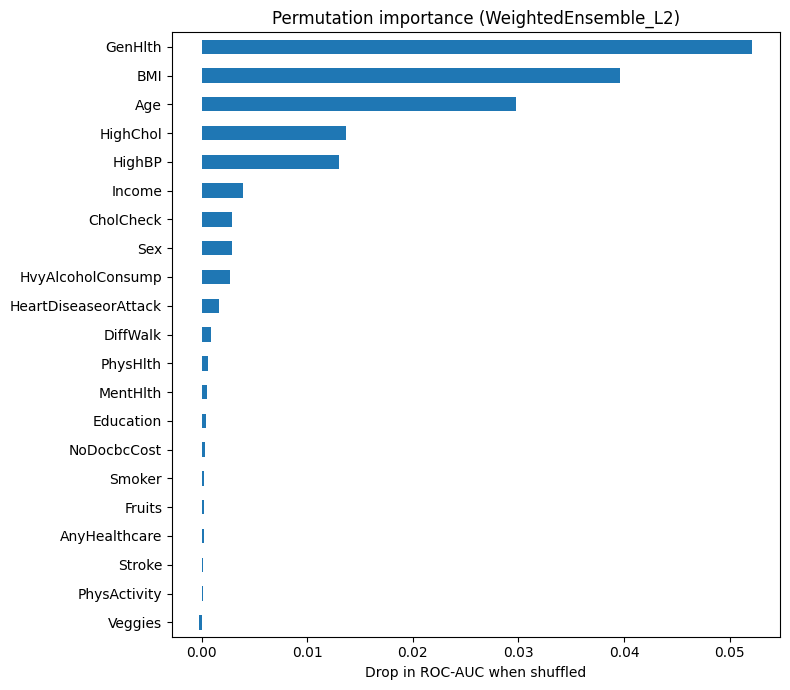

In [9]:
importance = predictor.feature_importance(test, model=best, subsample_size=5000, silent=True)
importance["importance"].sort_values().plot.barh(figsize=(8, 7), title=f"Permutation importance ({best})")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.tight_layout()
plt.show()

## 10. Conclusions

Results from the run on 2026-11-17 (11:04–12:08), decisions D-35 and D-36 in `DECISIONS.md`:

1. **AutoGluon does not clearly beat our CatBoost.** Test-set ROC-AUC: AutoGluon's best model (weighted ensemble)
   0.8261, its best single model (bagged CatBoost) 0.8260, our CatBoost 0.8248. The gain (+0.0012) is far below the
   +0.01 required by the decision rule (D-10), so **CatBoost stays** (D-36).
2. **At the 80% recall threshold the models are practically identical:** precision 33.3% vs. 33.1%, about 38% of
   people flagged for all three.
3. **All strong models land between 0.824 and 0.826**: CatBoost, LightGBM, XGBoost and both neural networks.
   Random forest and extra trees are slightly behind (0.814–0.818). This confirms that the data, not the choice of
   model, limits the score.
4. **The ensemble is expensive for its tiny gain:** ~3 GB on disk and ~9 s to predict 50k rows, vs. 0.01 s for our
   single CatBoost (~700× slower), plus AutoGluon and PyTorch as dependencies.
5. AutoGluon's best single model is a **bagged CatBoost** (8 CatBoost models trained on different folds, averaged).
   That is where its +0.001 comes from, which is worth knowing but not worth the extra complexity for now.
6. `ray` was not installed, so AutoGluon trained the folds one after another instead of in parallel (D-35). It
   still trained all model types; only a few extra model variants were skipped for lack of time.

**Next step:** shared input validation (`ml/validation.py`, step 3 in `PROJECT_PLAN.md`).